# Testes dos modelos: Laya × BERTimbau ao vivo

Este notebook carrega os dois modelos ajustados e roda uma bateria de reviews escritos para testar casos fáceis,
mistos e difíceis. Os modelos vêm de `outputs/` se você os treinou; senão, são baixados do Hugging Face:

- [RenatoSpessotto/laya-aspectos-reviews-ptbr](https://huggingface.co/RenatoSpessotto/laya-aspectos-reviews-ptbr)
- [RenatoSpessotto/bertimbau-aspectos-reviews-ptbr](https://huggingface.co/RenatoSpessotto/bertimbau-aspectos-reviews-ptbr)

Roda em CPU ou MPS em menos de um minuto, depois do download (~1 GB).

Para cada review o notebook mostra o rótulo e a confiança de cada aspecto, e se a cascata decidiria sozinha
(menor confiança ≥ 0,75) ou mandaria o review ao Claude. No fim, asserts verificam os casos óbvios.

In [1]:
import os, sys, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from review_intel.core.schema import ASPECTS, aspect_labels
from review_intel.models.registry import default_source, load

THRESHOLD = 0.75
print({m: default_source(m) for m in ("laya-ft", "bertimbau")})
models = {"Laya": load("laya-ft"), "BERTimbau": load("bertimbau")}

{'laya-ft': '/Users/renatospessotto/Documents/Portfólio/github/review-intelligence-ptbr/outputs/laya-ft', 'bertimbau': '/Users/renatospessotto/Documents/Portfólio/github/review-intelligence-ptbr/outputs/bertimbau-multiaspecto'}


/Users/renatospessotto/Documents/Portfólio/github/review-intelligence-ptbr/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1028 23:08:11.832000 56645 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## Bateria de testes

`esperado` traz só os aspectos com resposta inequívoca; os demais ficam livres. Os casos `difícil` (ironia, texto
curtíssimo, fora do domínio) não entram nos asserts: servem para ver como a confiança se comporta.

In [2]:
CASES = [
    # (tipo, review, rótulos esperados)
    ("fácil",   "Chegou rapidinho e o produto é excelente, recomendo!",            {"entrega": "positivo", "produto": "positivo"}),
    ("fácil",   "Já passou 15 dias do prazo e até agora nada do meu pedido.",       {"entrega": "negativo"}),
    ("fácil",   "Vendedor não responde minhas mensagens, péssimo atendimento.",     {"atendimento": "negativo"}),
    ("fácil",   "Muito barato pela qualidade, preço excelente.",                    {"preco": "positivo"}),
    ("misto",   "Produto ótimo, mas chegou com 10 dias de atraso e a caixa toda amassada.",
                {"entrega": "negativo", "produto": "positivo", "embalagem": "negativo"}),
    ("misto",   "Entrega no prazo, bem embalado, mas o tamanho veio errado.",       {"entrega": "positivo", "produto": "negativo"}),
    ("difícil", "Parabéns, conseguiram entregar só um mês depois. Maravilha.",     {}),
    ("difícil", "ok",                                                              {}),
    ("difícil", "Recebi o produto.",                                               {}),
    ("difícil", "Qual a previsão do tempo para amanhã em São Paulo?",              {}),
]

rows = []
for kind, text, expected in CASES:
    for name, model in models.items():
        t0 = time.perf_counter()
        pred = model.predict([text])[0]
        ms = 1000 * (time.perf_counter() - t0)
        labels = aspect_labels(pred.analysis)
        low = min(pred.confidence.values())
        rows.append({
            "tipo": kind, "review": text, "modelo": name,
            **{a: f"{labels[a]} ({pred.confidence[a]:.0%})" for a in ASPECTS},
            "menor conf.": low, "cascata": "decide" if low >= THRESHOLD else "→ Claude", "ms": ms,
            "acertos": f"{sum(labels[a] == v for a, v in expected.items())}/{len(expected)}" if expected else "-",
            "_labels": labels, "_conf": pred.confidence, "_expected": expected,
        })
res = pd.DataFrame(rows)
view = res.drop(columns=[c for c in res if c.startswith("_")])
view.style.format({"menor conf.": "{:.0%}", "ms": "{:.0f}"}).hide(axis="index")

tipo,review,modelo,entrega,produto,atendimento,preco,embalagem,menor conf.,cascata,ms,acertos
fácil,"Chegou rapidinho e o produto é excelente, recomendo!",Laya,positivo (97%),positivo (99%),ausente (99%),ausente (99%),ausente (99%),97%,decide,178,2/2
fácil,"Chegou rapidinho e o produto é excelente, recomendo!",BERTimbau,positivo (99%),positivo (99%),ausente (99%),ausente (100%),ausente (100%),99%,decide,16,2/2
fácil,Já passou 15 dias do prazo e até agora nada do meu pedido.,Laya,negativo (98%),ausente (99%),ausente (92%),ausente (99%),ausente (99%),92%,decide,65,1/1
fácil,Já passou 15 dias do prazo e até agora nada do meu pedido.,BERTimbau,negativo (98%),ausente (98%),ausente (97%),ausente (100%),ausente (100%),97%,decide,107,1/1
fácil,"Vendedor não responde minhas mensagens, péssimo atendimento.",Laya,ausente (97%),ausente (98%),negativo (98%),ausente (98%),ausente (99%),97%,decide,78,1/1
fácil,"Vendedor não responde minhas mensagens, péssimo atendimento.",BERTimbau,ausente (84%),ausente (96%),negativo (94%),ausente (99%),ausente (99%),84%,decide,10,1/1
fácil,"Muito barato pela qualidade, preço excelente.",Laya,ausente (98%),positivo (95%),ausente (99%),positivo (98%),ausente (99%),95%,decide,61,1/1
fácil,"Muito barato pela qualidade, preço excelente.",BERTimbau,ausente (98%),positivo (80%),ausente (96%),positivo (100%),ausente (98%),80%,decide,146,1/1
misto,"Produto ótimo, mas chegou com 10 dias de atraso e a caixa toda amassada.",Laya,negativo (97%),positivo (98%),ausente (98%),ausente (99%),negativo (96%),96%,decide,71,3/3
misto,"Produto ótimo, mas chegou com 10 dias de atraso e a caixa toda amassada.",BERTimbau,negativo (91%),positivo (86%),ausente (98%),ausente (100%),negativo (56%),56%,→ Claude,10,3/3


## Resumo por modelo

In [3]:
summary = res.groupby("modelo").agg(
    acertos=("_expected", lambda s: sum(sum(res.loc[i, "_labels"][a] == v for a, v in e.items()) for i, e in s.items())),
    esperados=("_expected", lambda s: sum(len(e) for e in s)),
    decide_sozinho=("cascata", lambda s: (s == "decide").mean()),
    conf_media_dificeis=("menor conf.", lambda s: s[res.loc[s.index, "tipo"] == "difícil"].mean()),
    conf_media_faceis=("menor conf.", lambda s: s[res.loc[s.index, "tipo"] == "fácil"].mean()),
    ms_mediana=("ms", "median"),
)
summary

,acertos,esperados,decide_sozinho,conf_media_dificeis,conf_media_faceis,ms_mediana
modelo,,,,,,
BERTimbau,10,10,0.6,0.773793,0.901283,14.018688
Laya,10,10,0.9,0.745725,0.951525,63.826250


## Confiança por aspecto num review misto

"Produto ótimo, mas chegou com 10 dias de atraso e a caixa toda amassada." Os dois modelos acertam os três aspectos
citados, mas não com a mesma certeza.

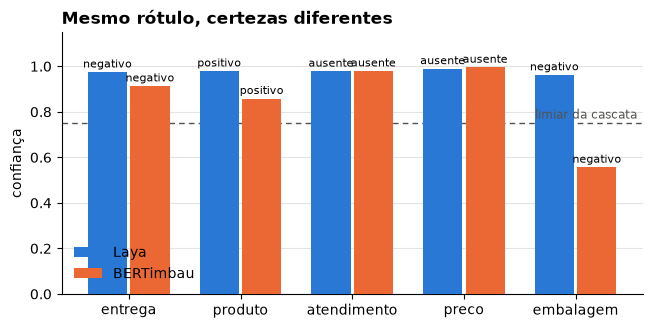

In [4]:
mixed = res[res["review"].str.startswith("Produto ótimo")]
COLORS = {"Laya": "#2a78d6", "BERTimbau": "#eb6834"}
x = np.arange(len(ASPECTS)); w = 0.38
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for i, (_, r) in enumerate(mixed.iterrows()):
    vals = [r["_conf"][a] for a in ASPECTS]
    bars = ax.bar(x + (i - 0.5) * w, vals, w * 0.92, color=COLORS[r["modelo"]], label=r["modelo"], zorder=3)
    for b, a in zip(bars, ASPECTS):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, r["_labels"][a], ha="center", fontsize=8, rotation=0)
ax.axhline(THRESHOLD, color="#52514e", linewidth=1, linestyle=(0, (4, 3)))
ax.text(len(ASPECTS) - 0.45, THRESHOLD + 0.02, "limiar da cascata", fontsize=8.5, color="#52514e", ha="right")
ax.set_xticks(x, ASPECTS); ax.set_ylim(0, 1.15); ax.set_ylabel("confiança")
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.grid(axis="y", color="#e4e3df"); ax.set_axisbelow(True); ax.legend(frameon=False, loc="lower left")
ax.set_title("Mesmo rótulo, certezas diferentes", loc="left", fontweight="bold")
plt.show()

## Asserts de sanidade

In [5]:
for _, r in res.iterrows():
    assert all(0.0 <= c <= 1.0 for c in r["_conf"].values()), r["review"]
    assert set(r["_labels"]) == set(ASPECTS)

# casos fáceis e mistos: os dois modelos acertam todos os aspectos inequívocos
for _, r in res[res["tipo"] != "difícil"].iterrows():
    wrong = {a: (r["_labels"][a], v) for a, v in r["_expected"].items() if r["_labels"][a] != v}
    assert not wrong, f"{r['modelo']} errou em '{r['review']}': {wrong}"

# o review misto separa entrega (negativa) de produto (positivo) nos dois modelos
for _, r in mixed.iterrows():
    assert r["_labels"]["entrega"] == "negativo" and r["_labels"]["produto"] == "positivo"

# BERTimbau (110M) é mais rápido que o Laya (322M)
med = res.groupby("modelo")["ms"].median()
assert med["BERTimbau"] < med["Laya"], med
print("todos os asserts passaram")

todos os asserts passaram


## Opcional: comparar com o Claude

Precisa de `ANTHROPIC_API_KEY` no `.env` e custa frações de centavo. Para rodar, defina `RUN_CLAUDE=1`.

In [6]:
from review_intel.core.env import load_dotenv
load_dotenv()
if os.environ.get("RUN_CLAUDE") == "1":
    claude = load("claude")
    preds = claude.predict([c[1] for c in CASES])
    display(pd.DataFrame([{"review": c[1], **aspect_labels(p.analysis)} for c, p in zip(CASES, preds)]))
else:
    print("pulado (defina RUN_CLAUDE=1 para rodar)")

pulado (defina RUN_CLAUDE=1 para rodar)
